# 03 — Univariate Forecasting
Forecast the selected lithium carbonate price using only its own past values. This provides the baseline against which multivariate models will be compared.

In [18]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../../Data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# All imputation/scaling is fitted inside each training fold.
def model_bank():
    return {
        "Linear Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LinearRegression()
        ),
        "KNN": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            KNeighborsRegressor(n_neighbors=8, weights="distance")
        ),
        "SVR": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVR(kernel="rbf", C=1.0, epsilon=0.1)
        ),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=200, max_depth=4,
                min_samples_split=10, min_samples_leaf=5,
                max_features=0.7, random_state=RANDOM_STATE
            )
        ),
        "Gradient Boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            GradientBoostingRegressor(
                n_estimators=100, learning_rate=0.03,
                max_depth=2, min_samples_leaf=5,
                subsample=0.8, loss="huber",
                random_state=RANDOM_STATE
            )
        ),
    }

PARAM_GRIDS = {
    "KNN": {
        "kneighborsregressor__n_neighbors": [5, 8, 12],
        "kneighborsregressor__weights": ["uniform", "distance"]
    },
    "SVR": {
        "svr__C": [0.1, 1.0, 10.0],
        "svr__epsilon": [0.1, 0.5, 1.0]
    },
    "Random Forest": {
        "randomforestregressor__max_depth": [3, 4, 5],
        "randomforestregressor__min_samples_leaf": [3, 5, 8]
    },
    "Gradient Boosting": {
        "gradientboostingregressor__n_estimators": [50, 100, 150],
        "gradientboostingregressor__learning_rate": [0.01, 0.03, 0.05],
        "gradientboostingregressor__max_depth": [1, 2, 3]
    }
}

def fit_with_time_series_cv(name, estimator, X_train, y_train):
    """Tune on chronological folds inside training data; never use the final test set."""
    if name not in PARAM_GRIDS:
        estimator.fit(X_train, y_train)
        return estimator, np.nan, {}
    cv = TimeSeriesSplit(n_splits=4)
    search = GridSearchCV(
        estimator=estimator,
        param_grid=PARAM_GRIDS[name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    return search.best_estimator_, -search.best_score_, search.best_params_

def score_predictions(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": mean_squared_error(y_true, pred) ** 0.5,
        "R2": r2_score(y_true, pred)
    }


## 1. Forecast horizons and model benchmark

In [19]:

def make_supervised(horizon=1, n_lags=12, exog_cols=None):
    """
    Create a univariate forecasting dataset using historical
    lithium carbonate prices.

    horizon=1: predict the current month using previous months.
    horizon=3: predict two months beyond the feature month.
    """
    X = pd.DataFrame(index=df.index)

    # Create historical target-price predictors
    for lag in range(1, n_lags + 1):
        X[f"Target_lag_{lag}"] = df[TARGET].shift(lag)

    # Optional explanatory variables (not used in Notebook 03)
    if exog_cols is not None:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = df[col].shift(lag)

    # Align predictors with the future target
    y = df[TARGET].shift(-(horizon - 1))

    # Remove rows without a known target
    valid = y.notna()
    X = X.loc[valid]
    y = y.loc[valid]

    return X, y


def split_time(X, y, train_fraction=0.80):
    """
    Chronological 80/20 train-test split.
    Does not shuffle observations.
    """
    split_index = int(len(X) * train_fraction)

    X_train = X.iloc[:split_index]
    X_test = X.iloc[split_index:]

    y_train = y.iloc[:split_index]
    y_test = y.iloc[split_index:]

    return X_train, X_test, y_train, y_test


In [20]:
HORIZONS = [1, 3, 6, 12]
results, predictions = [], {}
for h in HORIZONS:
    X, y = make_supervised(horizon=h, n_lags=12, exog_cols=None)
    X_train, X_test, y_train, y_test = split_time(X, y)
    for name, model in model_bank().items():
        fitted_model, cv_rmse, best_params = fit_with_time_series_cv(
            name, model, X_train, y_train
        )
        pred = fitted_model.predict(X_test)
        row = {
            "Horizon (months)": h,
            "Model": name,
            "CV RMSE": cv_rmse,
            "Best parameters": str(best_params),
            **score_predictions(y_test, pred)
        }
        results.append(row)
        predictions[(h, name)] = (y_test, pred)
results = pd.DataFrame(results).sort_values(["Horizon (months)", "RMSE"])
display(results)

,Horizon (months),Model,CV RMSE,Best parameters,MAE,RMSE,R2
4,1,Gradient Boosting,80067.464414,{'gradientboostingregressor__learning_rate': 0...,18165.606381,26983.329366,0.780488
3,1,Random Forest,83132.267232,"{'randomforestregressor__max_depth': 5, 'rando...",25648.825786,40705.422562,0.500458
0,1,Linear Regression,NaN,{},27361.478327,43366.078775,0.433020
1,1,KNN,80016.297658,"{'kneighborsregressor__n_neighbors': 5, 'kneig...",40140.438833,65212.196372,-0.282108
2,1,SVR,103151.465113,"{'svr__C': 10.0, 'svr__epsilon': 1.0}",75396.922908,94865.582870,-1.713216
6,3,KNN,84525.458471,"{'kneighborsregressor__n_neighbors': 12, 'knei...",51101.711378,65937.920833,-0.310803
7,3,SVR,103152.849527,"{'svr__C': 10.0, 'svr__epsilon': 0.1}",74882.346286,94471.983136,-1.690749
5,3,Linear Regression,NaN,{},63423.358292,97317.204186,-1.855264
8,3,Random Forest,88963.397650,"{'randomforestregressor__max_depth': 3, 'rando...",61540.942369,101197.381221,-2.087490
9,3,Gradient Boosting,87109.911882,{'gradientboostingregressor__learning_rate': 0...,63926.953246,106293.774942,-2.406299


## 2. Best model by horizon

In [21]:
best = results.loc[results.groupby("Horizon (months)")["RMSE"].idxmin()].sort_values("Horizon (months)")
display(best)

,Horizon (months),Model,CV RMSE,Best parameters,MAE,RMSE,R2
4,1,Gradient Boosting,80067.464414,{'gradientboostingregressor__learning_rate': 0...,18165.606381,26983.329366,0.780488
6,3,KNN,84525.458471,"{'kneighborsregressor__n_neighbors': 12, 'knei...",51101.711378,65937.920833,-0.310803
14,6,Gradient Boosting,95162.540330,{'gradientboostingregressor__learning_rate': 0...,40278.114217,52399.911001,0.113978
19,12,Gradient Boosting,100946.450649,{'gradientboostingregressor__learning_rate': 0...,36683.671110,54718.073779,-0.273677


## 3. Plot one-month-ahead predictions

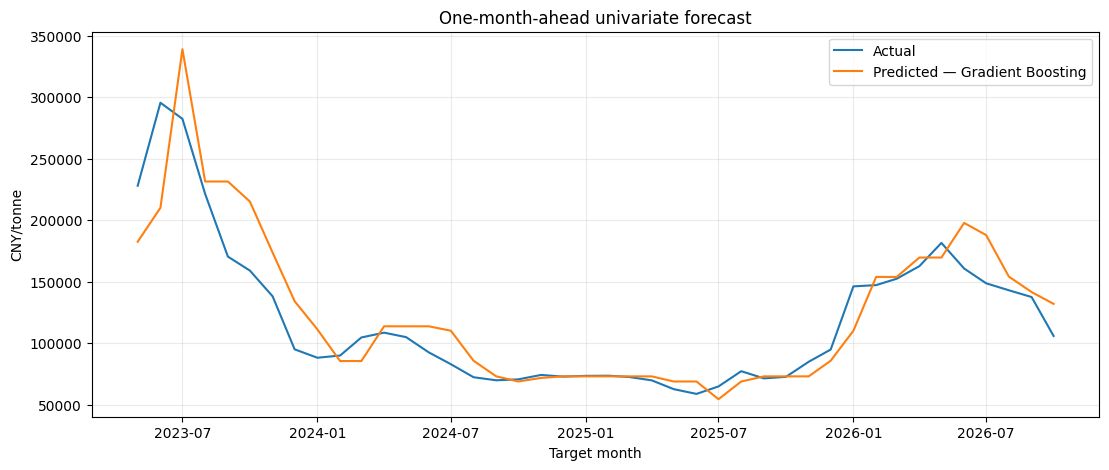

In [22]:
h=1
best_name = best.loc[best["Horizon (months)"]==h, "Model"].iloc[0]
y_test, pred = predictions[(h, best_name)]
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(y_test.index, y_test.values, label="Actual")
ax.plot(y_test.index, pred, label=f"Predicted — {best_name}")
ax.set(title="One-month-ahead univariate forecast", xlabel="Target month", ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()

,Fold,Training observations,Training RMSE,Validation RMSE
0,1,28,2334.216074,3976.222734
1,2,54,2215.500490,63077.060774
2,3,80,23953.552870,52145.439174
3,4,106,31418.900859,31556.723114
4,5,132,30207.651549,303841.533091


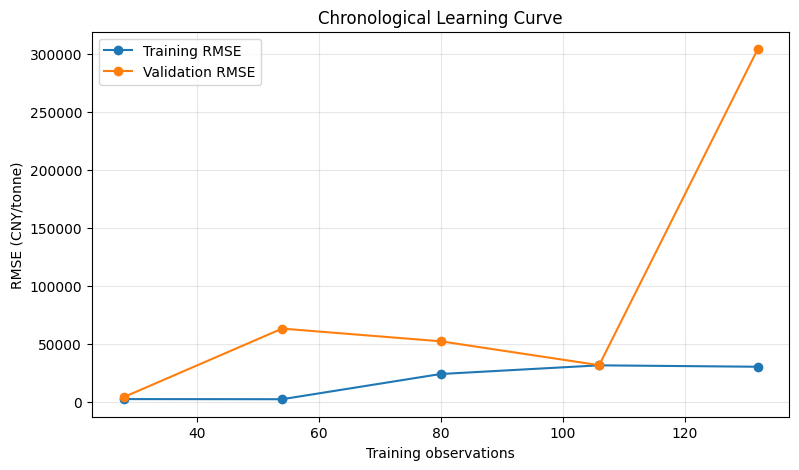

In [24]:

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def chronological_learning_curve(model, X, y, n_splits=5):

    splitter = TimeSeriesSplit(n_splits=n_splits)
    records = []

    for fold, (train_idx, val_idx) in enumerate(splitter.split(X), 1):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]
        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        fitted = clone(model)
        fitted.fit(X_tr, y_tr)

        train_pred = fitted.predict(X_tr)
        val_pred = fitted.predict(X_val)

        records.append({
            "Fold": fold,
            "Training observations": len(train_idx),
            "Training RMSE": np.sqrt(
                mean_squared_error(y_tr, train_pred)
            ),
            "Validation RMSE": np.sqrt(
                mean_squared_error(y_val, val_pred)
            )
        })

    return pd.DataFrame(records)


learning_results = chronological_learning_curve(
    fitted_model,
    X_train,
    y_train
)

display(learning_results)

plt.figure(figsize=(9, 5))
plt.plot(
    learning_results["Training observations"],
    learning_results["Training RMSE"],
    marker="o",
    label="Training RMSE"
)
plt.plot(
    learning_results["Training observations"],
    learning_results["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Training observations")
plt.ylabel("RMSE (CNY/tonne)")
plt.title("Chronological Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Save results

In [23]:
results.to_csv("../../Results/univariate_model_comparison.csv", index=False)
print("Saved ../../Results/univariate_model_comparison.csv")

Saved ../../Results/univariate_model_comparison.csv


## Interpretation notes
- The test set is the final chronological 20% of supervised observations.
- Imputation is fitted only on training data through the pipeline.
- For horizon h, predictors are lagged observations and the target is shifted h months ahead.
- A random train/test split is inappropriate for this time-series forecasting task.